# Implementing GoogleNet

Assignment from *Programming Exercises Chapter 14*, Stijn Lievens and Simon De Gheselle (June 26, 2026). Each part has its own empty code cell. Add written answers beneath the relevant cell. No solutions are included.

## Setup
Add your imports and setup here.

## 3.1 Introduction

Build GoogLeNet and test it on CIFAR10. Refer to the architecture diagrams below. The first Inception module uses 16 filters in its 5 × 5 reduction branch, correcting the book’s 12. Original paper: https://www.cv-foundation.org/openaccess/content_cvpr_2015/papers/Szegedy_Going_Deeper_With_2015_CVPR_paper.pdf. All Inception convolutions use ReLU, stride 1, and same padding; its max pooling also uses stride 1 and same padding. Concatenate along the default axis, -1.

## 3.2 Implement the Inception Module

Subclass `keras.layers.Layer` as `InceptionModule`. Start from Figure 6 below. Constructor parameters: `filters11`, `filters33_reduce`, `filters33`, `filters55_reduce`, `filters55`, `filters_pool_proj`, `use_batch_norm=True`, and `**kwargs`.

Complete `__init__`: the left convolution (`self.conv11`) is supplied. Create the other five convolutions using the filter names in Figure 5, the right max pooling layer, and a batch normalization layer when requested.

Complete `call`: apply the four paths from Figure 5, concatenate their tensors, optionally apply batch normalization, and return the result. Spatial dimensions remain equal and output channels sum across paths. No custom `build` is needed because built-in layers provide it.

### Part 4

Test with `keras.ops.full(shape=(1, 128, 128, 3), fill_value=0.5)`. Instantiate with `filters11=64`, `filters33_reduce=96`, `filters33=128`, `filters55_reduce=16`, `filters55=32`, `filters_pool_proj=32`, and `use_batch_norm=False`. Print and explain the output shape. Use `keras.Sequential([inception_module]).summary()` to inspect parameter counts.

## 3.3 Implement the GoogleNet Model

Implement `get_googlenet_model(input_shape, num_classes, use_batch_norm=True, **kwargs)` using Sequential and Figure 4. Use max pooling with pool size (3, 3), stride (2, 2), same padding. Add in order: Input; first convolution; optional batch normalization; max pooling; second and third convolutions; optional batch normalization; max pooling; two Inception modules; max pooling; five Inception modules; max pooling; two Inception modules; global average pooling; dropout; output Dense with suitable units and activation. Prefer a loop over repeated Inception code.

Add the supplied preprocessing model: Input `(32, 32, 3)`, resize to `HEIGHT = WIDTH = 128`, then `Rescaling(scale=1/127.5, offset=-1)`. Create `model = get_googlenet_model(input_shape=(128,128,3), num_classes=10, use_batch_norm=False, name="GoogLeNet")`. Inspect its summary and combine with preprocessing as `full_model = keras.Sequential([preprocess_layer, model])`. Understand the preprocessing.

## 3.4 Compile the Model

Compile with Adam, learning rate 0.001, the appropriate classification loss, and accuracy.

## 3.5 Prepare the Training Data

Load CIFAR10 using the previous exercise. Create the same training, validation, and test sets.

## 3.6 Train the Model

Train for many epochs with early stopping, batch size 128, and validation data.

## 3.7 Evaluate the Model

Use `evaluate()` to measure test performance.

## 3.8 Improve the Model

Introduce batch normalization. Compile, train, and evaluate again.

Create Sequential data augmentation using RandomFlip, RandomRotation, and RandomContrast (see the book). Place it before preprocessing. Compile, train, and evaluate again.

After training stops, decrease the learning rate by a factor of 10. Compile and continue training the existing model, preserving its weights.

### Part 4

Decrease the learning rate by another factor of 10. Compile and continue training the existing model. This may give no further improvement.

### Part 5

Use Monte Carlo dropout (book page 397). Process the test set in batches of 500 to avoid running out of memory and use 20 samples for speed. The assignment suggests approximately 90% test accuracy is achievable with these techniques.

## Original figures and starter-code reference
The assignment above is editable Markdown. These original pages preserve diagram labels and the formatting of supplied code.

### Assignment — source page 14

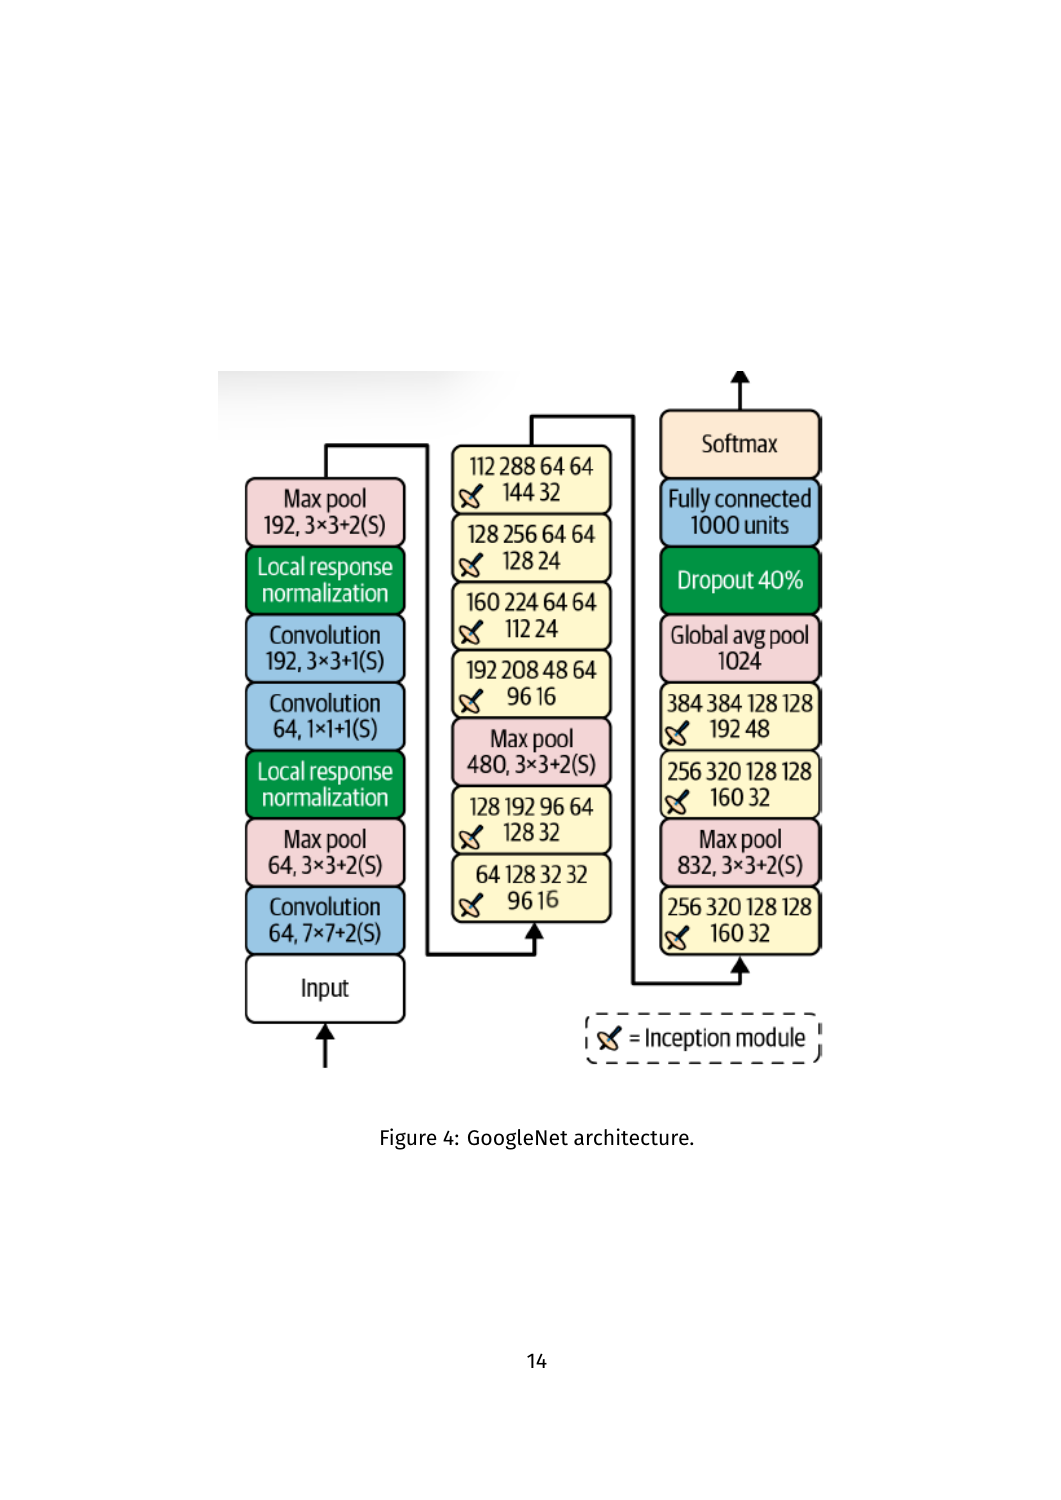

### Assignment — source page 15

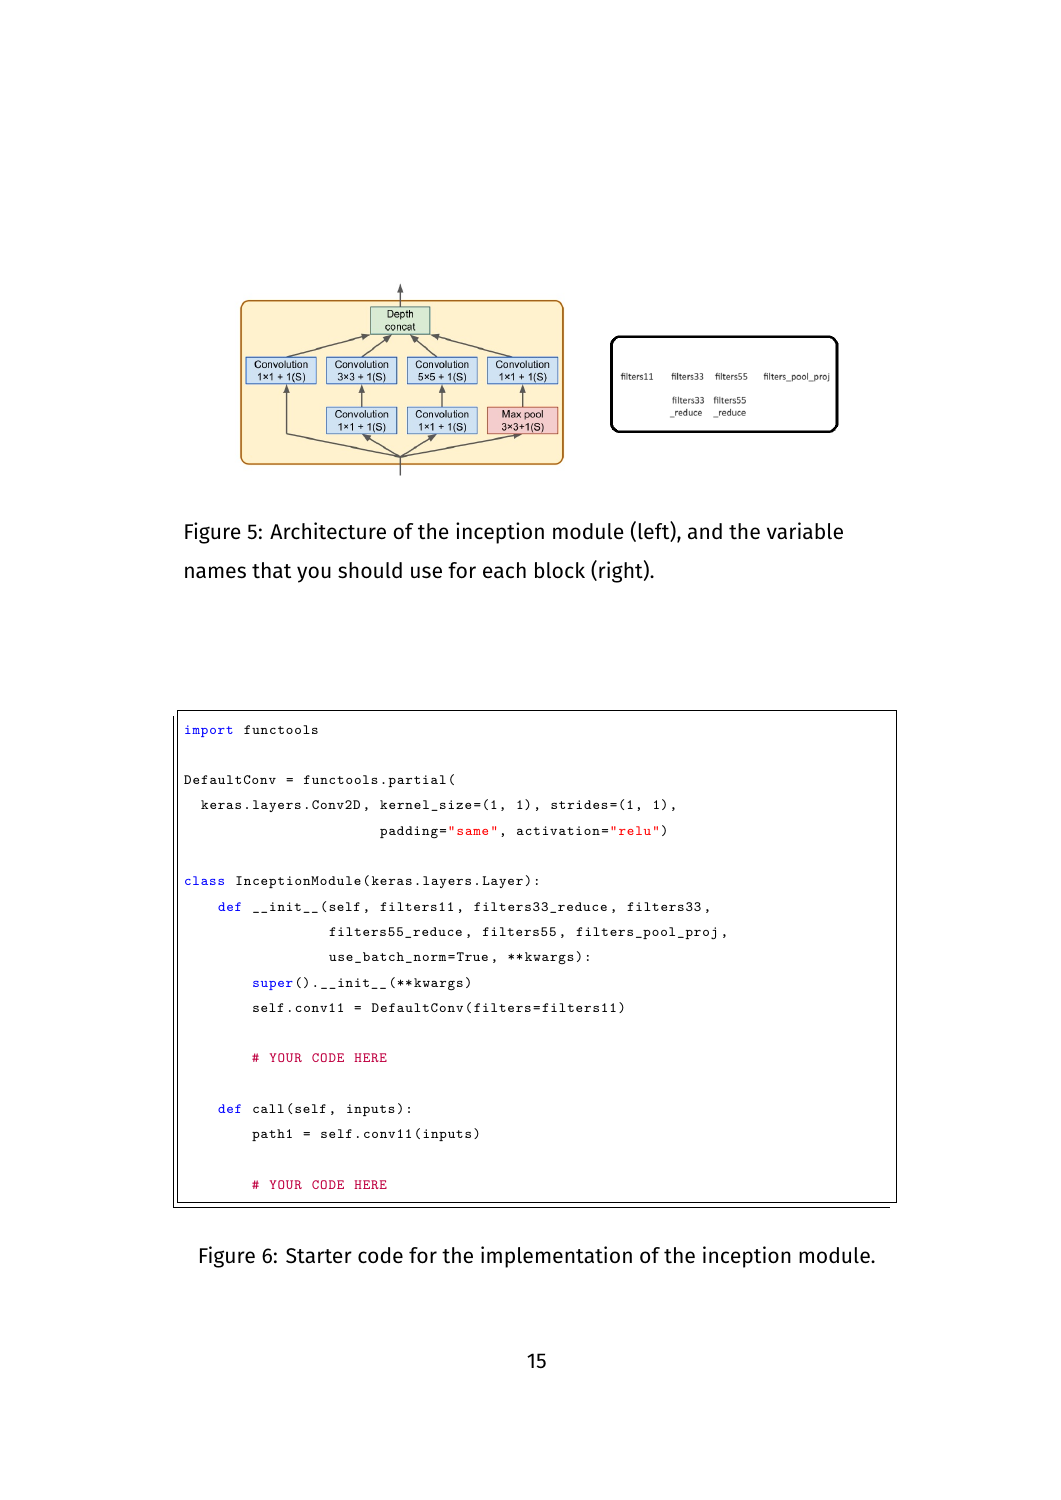